### Step 1 : Connect to MongoDB Server

In [1]:
from pymongo import MongoClient
client = MongoClient("mongodb://localhost:27017/", serverSelectionTimeoutMS=5000)
try:
    client.admin.command("ping")
    print("MongoDB connected successfully!")
except Exception as e:
    print("MongoDB connection failed:", e)

MongoDB connected successfully!


### Step 2 : Create the MongoDB database and collection

In [2]:
db = client["EmployeeAttritionDB"]
employees = db["employees"]

print("Database name:", db.name)
print("Collection name:", employees.name)
print("MongoDB database and collection are ready.")

Database name: EmployeeAttritionDB
Collection name: employees
MongoDB database and collection are ready.


### Step 3 : Insert the CSV data into MongoDB

In [3]:
import pandas as pd
from pathlib import Path
dataset = Path("data") / "HR-Employee-Attrition.csv"
df = pd.read_csv(dataset)

records = df.to_dict(orient="records")

employees.delete_many({})

if records:
    result = employees.insert_many(records)
    print("Records inserted:", len(result.inserted_ids))
else:
    print("No records found in the CSV file.")

print("Dataset shape:", df.shape)
print("MongoDB document count:", employees.count_documents({}))
print("Columns:", df.columns.tolist())

Records inserted: 1470
Dataset shape: (1470, 36)
MongoDB document count: 1470
Columns: ['Age', 'Attrition', 'TravelCategory', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'Tenure', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'ExperienceGroup']


### Step 4 : Check the dataset using PyMongo

In [4]:
total_employees = employees.count_documents({})
print("Total employees:", total_employees)

# Display one employee document
print("Sample employee record:")
print(employees.find_one({}, {"_id": 0}))

print("Attrition distribution:")
pipeline = [
    {
        "$group": {
            "_id": "$Attrition",
            "count": {"$sum": 1}
        }
    }
]
for record in employees.aggregate(pipeline):
    print(record["_id"], ":", record["count"])

Total employees: 1470
Sample employee record:
{'Age': 41, 'Attrition': 'Yes', 'TravelCategory': 'Travel_Rarely', 'DailyRate': 1102, 'Department': 'Sales', 'DistanceFromHome': 1, 'Education': 2, 'EducationField': 'Life Sciences', 'EmployeeCount': 1, 'EmployeeNumber': 1, 'EnvironmentSatisfaction': 2, 'Gender': 'Female', 'HourlyRate': 94, 'JobInvolvement': 3, 'JobLevel': 2, 'JobRole': 'Sales Executive', 'JobSatisfaction': 4, 'MaritalStatus': 'Single', 'MonthlyIncome': 5993, 'MonthlyRate': 19479, 'NumCompaniesWorked': 8, 'Over18': 'Y', 'OverTime': 'Yes', 'PercentSalaryHike': 11, 'PerformanceRating': 3, 'RelationshipSatisfaction': 1, 'StandardHours': 80, 'StockOptionLevel': 0, 'TotalWorkingYears': 8, 'TrainingTimesLastYear': 0, 'WorkLifeBalance': 1, 'Tenure': 6, 'YearsInCurrentRole': 4, 'YearsSinceLastPromotion': 0, 'YearsWithCurrManager': 5, 'ExperienceGroup': 'Mid-level'}
Attrition distribution:
No : 1233
Yes : 237


### Step 5 : Check missing values and duplicate records

In [5]:
df = pd.DataFrame(
    list(employees.find({}, {"_id": 0}))
)
print("Missing values :", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Attrition values:")
print(df["Attrition"].value_counts())

Missing values : 0
Duplicate rows: 0
Attrition values:
Attrition
No     1233
Yes     237
Name: count, dtype: int64


### Step 6 : Prepare the features and target

In [6]:
data = df.copy()
# Remove the employee identifier because it is not a useful predictor
data.drop(columns=["EmployeeNumber"], inplace=True, errors="ignore")

# Remove constant columns that provide no predictive information
constant_cols = [
    col for col in data.columns
    if data[col].nunique(dropna=False) <= 1
]
data.drop(columns=constant_cols, inplace=True)

print("Constant columns removed:", constant_cols)
print("Remaining columns:", len(data.columns))
print("Remaining shape:", data.shape)

X = data.drop(columns=["Attrition"])
y = data["Attrition"].map({"No": 0, "Yes": 1})

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget values:")
print(y.value_counts(dropna=False))

Constant columns removed: ['EmployeeCount', 'Over18', 'StandardHours']
Remaining columns: 32
Remaining shape: (1470, 32)

Feature shape: (1470, 31)
Target shape: (1470,)

Target values:
Attrition
0    1233
1     237
Name: count, dtype: int64


### Step 7 : Identify numerical and categorical columns

In [7]:
numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", len(numeric_cols))
print(numeric_cols)

print("\nCategorical columns:", len(categorical_cols))
print(categorical_cols)

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

Numerical columns: 23
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'Tenure', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Categorical columns: 8
['TravelCategory', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime', 'ExperienceGroup']

Missing values in X: 0
Missing values in y: 0


### Step 8 : Preprocessing

In [8]:
# Convert categorical columns into numerical columns
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Original features:", X.shape[1])
print("Features after encoding:", X_encoded.shape[1])
print("\nPreprocessing completed!")
print("Encoded dataset shape:", X_encoded.shape)
display(X_encoded.head(10))

Original features: 31
Features after encoding: 46

Preprocessing completed!
Encoded dataset shape: (1470, 46)


,Age,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,MaritalStatus_Married,MaritalStatus_Single,OverTime_Yes,ExperienceGroup_Fresher,ExperienceGroup_Mid-level
0,41,1102,1,2,2,94,3,2,4,5993,...,0,0,0,1,0,0,1,1,0,1
1,49,279,8,1,3,61,2,2,2,5130,...,0,0,1,0,0,1,0,0,0,1
2,37,1373,2,2,4,92,2,1,3,2090,...,0,0,0,0,0,0,1,1,0,1
3,33,1392,3,4,4,56,3,1,3,2909,...,0,0,1,0,0,1,0,1,0,1
4,27,591,2,1,1,40,3,1,2,3468,...,0,0,0,0,0,1,0,0,0,1
5,32,1005,2,2,4,79,3,1,4,3068,...,0,0,0,0,0,0,1,0,0,1
6,59,1324,3,3,3,81,4,1,1,2670,...,0,0,0,0,0,1,0,1,0,0
7,30,1358,24,1,4,67,3,1,3,2693,...,0,0,0,0,0,0,0,0,1,0
8,38,216,23,3,4,44,2,3,3,9526,...,1,0,0,0,0,0,1,0,0,1
9,36,1299,27,3,3,94,3,2,3,5237,...,0,0,0,0,0,1,0,0,0,0


### Step 9 : Split the data into training and testing sets

In [9]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Data split completed successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training features:", X_train.shape[1])
print("Testing features:", X_test.shape[1])

Data split completed successfully!
Training records: 1029
Testing records: 441
Training features: 46
Testing features: 46


### Step 10 : Train the Logistic Regression model

In [10]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        random_state=42
    )
)
model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


### Step 11 : Generate Prediction

In [11]:
y_pred = model.predict(X_test)

print("Actual values:", y_test.values[:10])
print("Predicted values:", y_pred[:10])
print("Total predictions:", len(y_pred))

Actual values: [0 0 0 0 0 0 0 0 0 0]
Predicted values: [0 0 0 0 0 0 0 0 0 0]
Total predictions: 441


### Step 12 : Evaluate the Logistic Regression model

In [ ]:
from sklearn.metrics import (
    accuracy_score,precision_score,recall_score,f1_score,mean_absolute_error,classification_report
)
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
mae = mean_absolute_error(y_test, y_pred)

print("Logistic Regression Model Evaluation")
print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")
print(f"MAE      : {mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))

Logistic Regression Model Evaluation
Accuracy : 0.8707 (87.07%)
Precision: 0.7059
Recall   : 0.3380
F1-score : 0.4571
MAE      : 0.1293

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.97      0.93       370
        Left       0.71      0.34      0.46        71

    accuracy                           0.87       441
   macro avg       0.80      0.66      0.69       441
weighted avg       0.86      0.87      0.85       441



### Step 13 : Train a Decision Tree model

In [15]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier(
    max_depth=6,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree model trained successfully.")
print("Total predictions:", len(dt_pred))

Decision Tree model trained successfully.
Total predictions: 441


### Step 14 : Evaluate the Decision Tree model

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    classification_report
)
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred, zero_division=0)
dt_recall = recall_score(y_test, dt_pred, zero_division=0)
dt_f1 = f1_score(y_test, dt_pred, zero_division=0)
dt_mae = mean_absolute_error(y_test, dt_pred)

print("Decision Tree model evaluation.")
print(f"Accuracy : {dt_accuracy:.4f} ({dt_accuracy * 100:.2f}%)")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-score : {dt_f1:.4f}")
print(f"MAE      : {dt_mae:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    dt_pred,
    target_names=["Stayed", "Left"],
    zero_division=0
))


Decision Tree model evaluation.
Accuracy : 0.7302 (73.02%)
Precision: 0.3125
Recall   : 0.5634
F1-score : 0.4020
MAE      : 0.2698

Classification Report:
              precision    recall  f1-score   support

      Stayed       0.90      0.76      0.83       370
        Left       0.31      0.56      0.40        71

    accuracy                           0.73       441
   macro avg       0.61      0.66      0.61       441
weighted avg       0.81      0.73      0.76       441



### Step 15 : Compare both models

In [17]:
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "MAE"],
    "Logistic Regression": [
        accuracy, precision, recall, f1, mae
    ],
    "Decision Tree": [
        dt_accuracy, dt_precision, dt_recall, dt_f1, dt_mae
    ]
})

print("Model Comparison:")
display(comparison.round(4))

Model Comparison:


,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.8707,0.7302
1,Precision,0.7059,0.3125
2,Recall,0.3380,0.5634
3,F1-score,0.4571,0.4020
4,MAE,0.1293,0.2698


### Step 16 : Improved Logistic Regression

In [18]:
improved_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )
)
improved_model.fit(X_train, y_train)
improved_pred = improved_model.predict(X_test)
print("Improved Logistic Regression model trained successfully.")

Improved Logistic Regression model trained successfully.


### Step 17 : Evaluate the Improved Logistic Regression

In [20]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error
)
improved_accuracy = accuracy_score(y_test, improved_pred)
improved_precision = precision_score(
    y_test, improved_pred, zero_division=0
)
improved_recall = recall_score(
    y_test, improved_pred, zero_division=0
)
improved_f1 = f1_score(
    y_test, improved_pred, zero_division=0
)
improved_mae = mean_absolute_error(y_test, improved_pred)

print("Improved Logistic Regression model evaluation.")
print(f"Accuracy : {improved_accuracy:.4f}")
print(f"Precision: {improved_precision:.4f}")
print(f"Recall   : {improved_recall:.4f}")
print(f"F1-score : {improved_f1:.4f}")
print(f"MAE      : {improved_mae:.4f}")

Improved Logistic Regression model evaluation.
Accuracy : 0.7800
Precision: 0.3917
Recall   : 0.6620
F1-score : 0.4921
MAE      : 0.2200


### Step 18 : Comparing all three models

In [21]:
final_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Improved Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy, improved_accuracy, dt_accuracy
    ],
    "Precision": [
        precision, improved_precision, dt_precision
    ],
    "Recall": [
        recall, improved_recall, dt_recall
    ],
    "F1-score": [
        f1, improved_f1, dt_f1
    ],
    "MAE": [
        mae, improved_mae, dt_mae
    ]
})

print("Final Model Comparison:")
display(final_comparison.round(4))

Final Model Comparison:


,Model,Accuracy,Precision,Recall,F1-score,MAE
0,Logistic Regression,0.8707,0.7059,0.3380,0.4571,0.1293
1,Improved Logistic Regression,0.7800,0.3917,0.6620,0.4921,0.2200
2,Decision Tree,0.7302,0.3125,0.5634,0.4020,0.2698


### Step 19 : Confusion Matrix of all three models

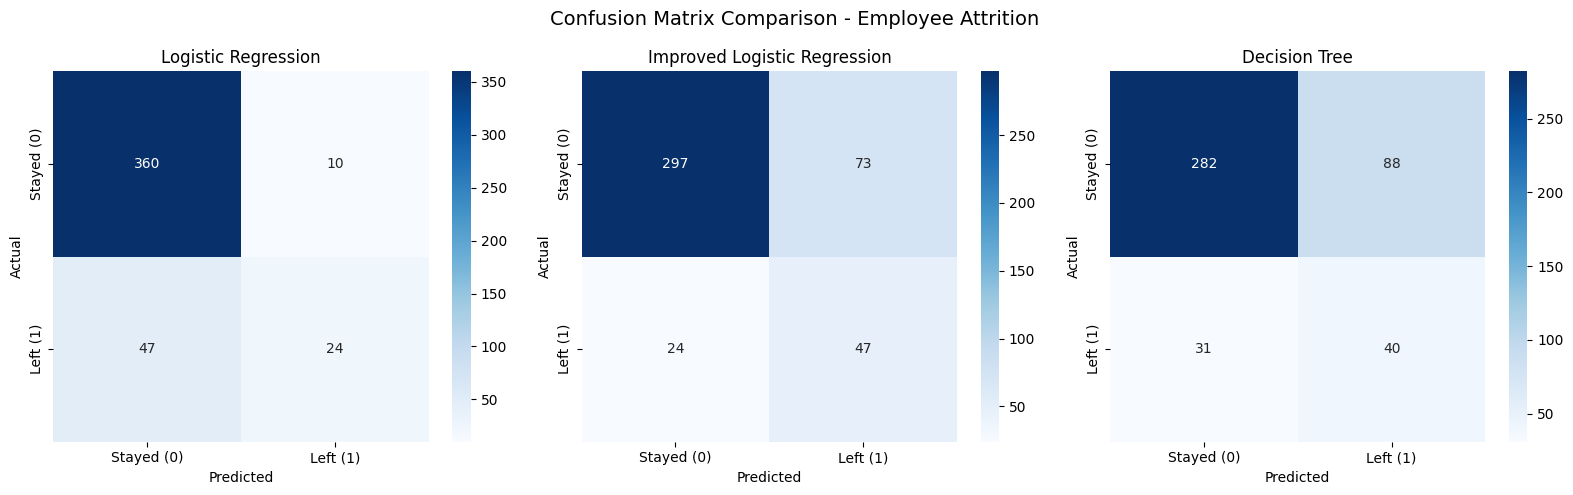

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

models = {
    "Logistic Regression": y_pred,
    "Improved Logistic Regression": improved_pred,
    "Decision Tree": dt_pred
}

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (model_name, predictions) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Stayed (0)", "Left (1)"],
        yticklabels=["Stayed (0)", "Left (1)"],
        ax=ax
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.suptitle("Confusion Matrix Comparison - Employee Attrition", fontsize=14)
plt.tight_layout()
plt.show()

### Step 20: Visualize the comparison

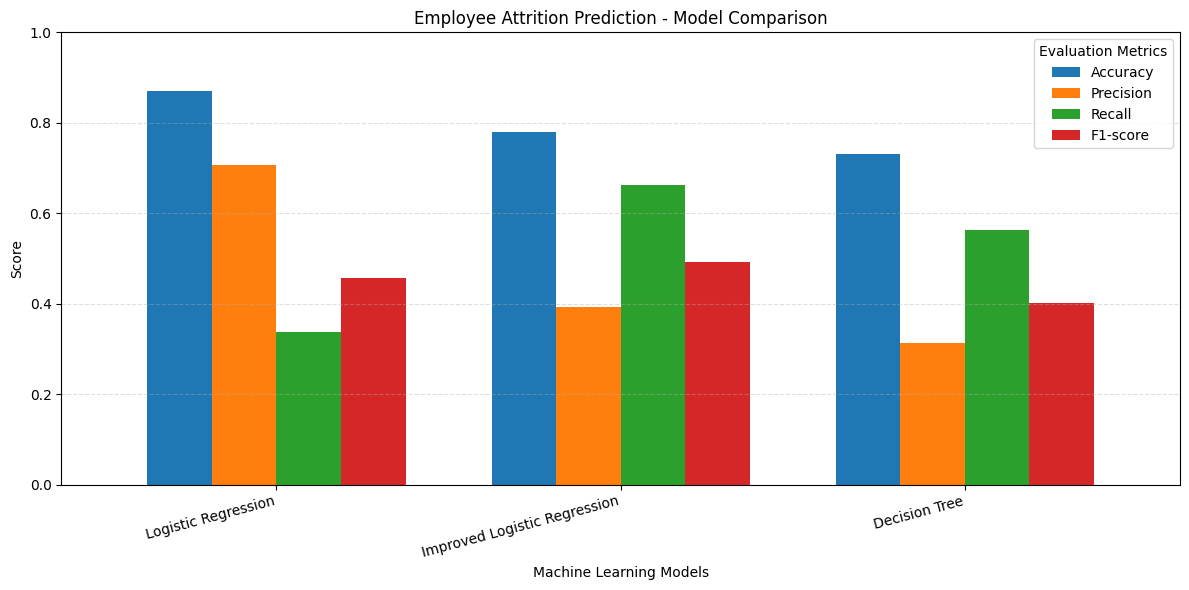

In [23]:
metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

plot_data = final_comparison.set_index("Model")[metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.75
)

plt.title("Employee Attrition Prediction - Model Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()